# Single Quantum Particle in a 1D Harmonic Oscilator


In [2]:
%pip install numpy
%pip install matplotlib
%pip install tqdm
%pip install statsmodels
%load_ext autoreload
%autoreload 2


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import math
import numpy as np
from single_particle import SingleParticleInHarmonicTrap
import matplotlib.pyplot as plt
from tqdm import tqdm 

Començarem definint les constants de l'experiment:

In [4]:
exp = SingleParticleInHarmonicTrap(
    alpha=1.0,
    mass=1,
    omega=2*math.pi,
    temperature=10,
)

Començarem mirant, per aquests paràmetres inicials, quin és el valor òptim de la desviació estàndard per al mètode de metropolis.

100
100


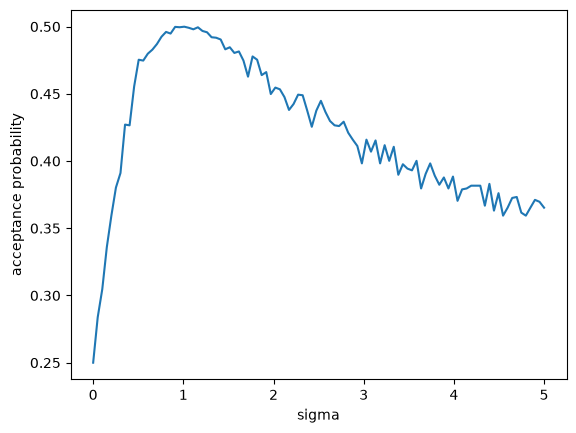

Optimal value of sigma: 1.0101010101010102; Acceptance probability = 0.491


In [5]:
optimal_sigma, prob = exp.find_optimal_sigma(verbose=True)
print(f"Optimal value of sigma: {optimal_sigma}; Acceptance probability = {prob}")

Now that we've found a good value of sigma, we can start sampling with the metropolis algorithm. To start, we're going to plot the density profile, which we expect to look like a gaussian distribution centered at zero.

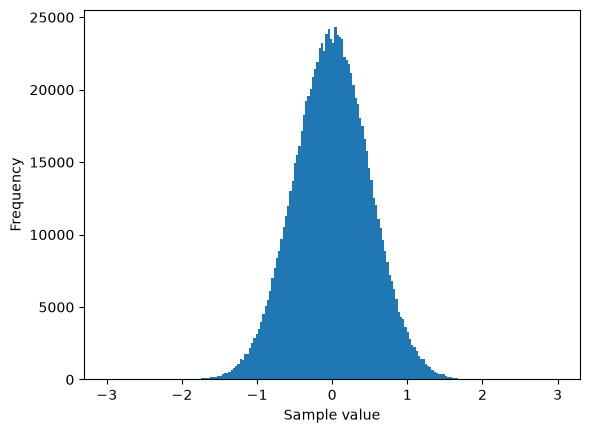

In [6]:
histogram = exp.draw_density_profile(nbins=200, _min=-3, _max=3, N=1_000_000)

We can also calculate the mean potential and kinetic energies, as well as the total energy for the current parameters.

Actually, the kinetic energy can be calculated in two different ways:
- Direct Estimator
- Aproximation using the Drift Force

In [7]:
N = 1_000_000
V = exp.average_potential_energy(N)
K_DIRECT = exp.average_kinetic_energy_direct_estimator(N)
K_DRIFT  = exp.average_kinetic_energy_drift_force(N)
E_DIRECT = K_DIRECT + V
E_DRIFT  = K_DRIFT + V

print(f"V = {V}")
print(f"K_DIRECT = {K_DIRECT}")
print(f"K_DRIFT = {K_DRIFT}")
print(f"E_DIRECT = {E_DIRECT}")
print(f"E_DRIFT = {E_DRIFT}")

V = 4.94321952639473
K_DIRECT = 0.012589509657381847
K_DRIFT = 0.012663713182662456
E_DIRECT = 4.955809036052112
E_DRIFT = 4.955883239577392


100it [00:30,  3.29it/s]


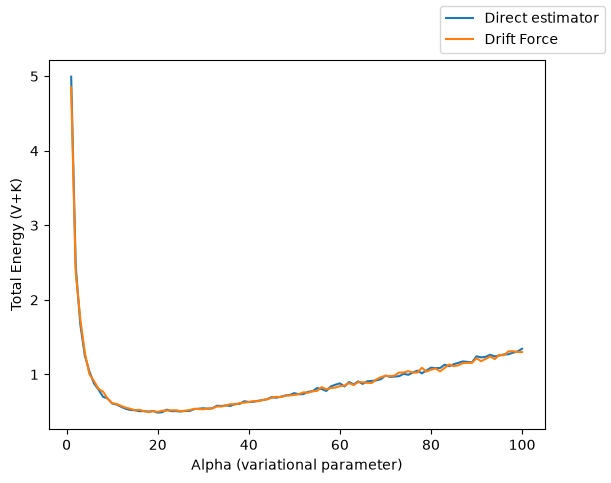

In [8]:
N = 20_000
NUM_CONFIGS = 100

alphas = np.linspace(1, 100, NUM_CONFIGS)

direct_energies = [0 for i in range(NUM_CONFIGS)] 
drift_energies = [0 for i in range(NUM_CONFIGS)]

for i, alpha in tqdm(enumerate(alphas)):
    exp.set_alpha(alpha)
    direct_energies[i] = exp.average_energy_direct_estimator(N)
    drift_energies[i] = exp.average_energy_drift_force(N)

fig = plt.figure()
_ = plt.plot(alphas, direct_energies, label="Direct estimator")
_ = plt.plot(alphas, drift_energies, label="Drift Force")
_ = plt.xlabel("Alpha (variational parameter)")
_ = plt.ylabel("Total Energy (V+K)")
_ = fig.legend()

In [9]:
ground_state_alpha = alphas[np.argmin(direct_energies[1:])]

print(f"Ground state alpha = {ground_state_alpha}" )
print(f"Ground state energy = {np.min(direct_energies[1:])}")

Ground state alpha = 19.0
Ground state energy = 0.48602413587637044


Clearly, they match, which validates that our montecarlo sampling is correct :D

Now, let's plot the Kinetic and Potential energy plots separately

0it [00:00, ?it/s]

100it [00:27,  3.62it/s]


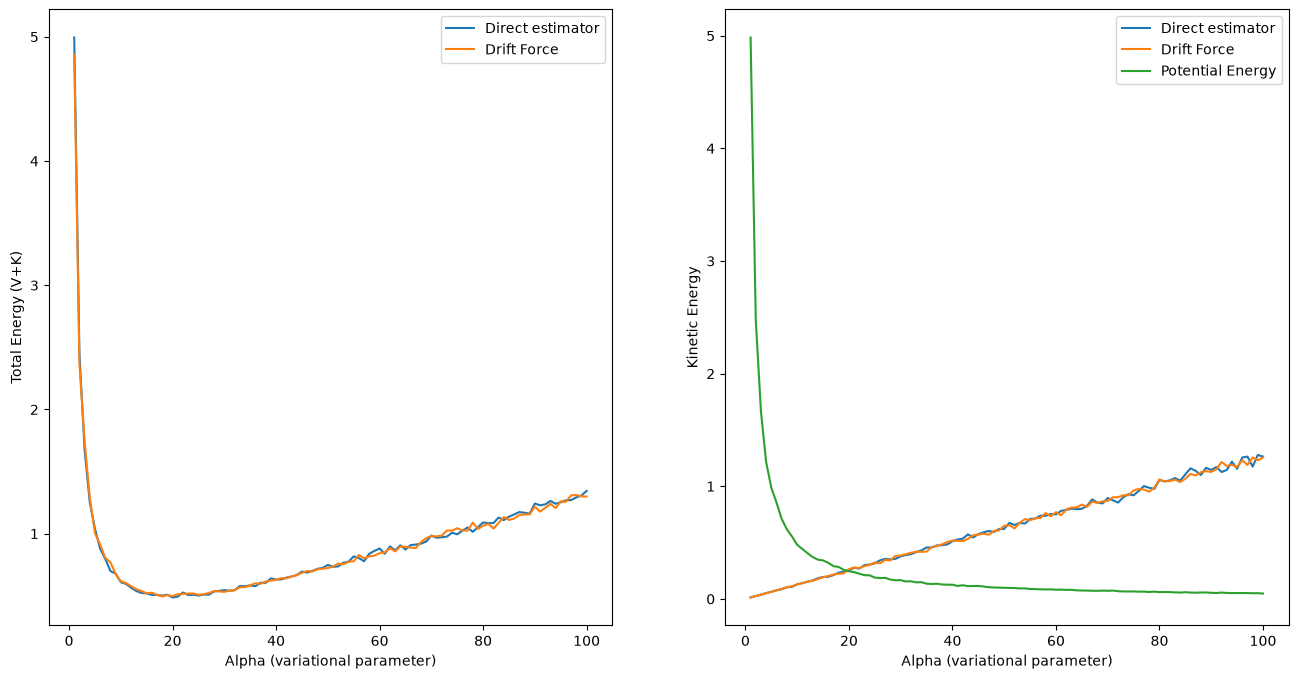

In [10]:
direct_K = [0 for i in range(NUM_CONFIGS)] 
drift_K = [0 for i in range(NUM_CONFIGS)]
V = [0 for i in range(NUM_CONFIGS)] 

for i, alpha in tqdm(enumerate(alphas)):
    exp.set_alpha(alpha)
    direct_K[i] = exp.average_kinetic_energy_direct_estimator(N)
    drift_K[i]  = exp.average_kinetic_energy_drift_force(N)
    V[i]        = exp.average_potential_energy(N)

fig = plt.figure(figsize=(16, 8))
ax1 = plt.subplot(1, 2, 1)
_ = plt.plot(alphas, direct_energies, label="Direct estimator")
_ = plt.plot(alphas, drift_energies, label="Drift Force")
_ = plt.xlabel("Alpha (variational parameter)")
_ = plt.ylabel("Total Energy (V+K)")
ax1.legend()

ax2 = plt.subplot(1, 2, 2)
_ = plt.plot(alphas, direct_K, label="Direct estimator")
_ = plt.plot(alphas, drift_K, label="Drift Force")
_ = plt.plot(alphas, V, label="Potential Energy")
_ = plt.xlabel("Alpha (variational parameter)")
_ = plt.ylabel("Kinetic Energy")
ax2.legend()

Now I'm going to perform some extra analysis making use of pyblock to aproximate the error in our samples.

In [11]:
direct_energies = [0 for i in range(NUM_CONFIGS)] 
drift_energies = [0 for i in range(NUM_CONFIGS)]
direct_errors = [0 for i in range(NUM_CONFIGS)] 
drift_errors = [0 for i in range(NUM_CONFIGS)]

for i, alpha in tqdm(enumerate(alphas)):
    exp.set_alpha(alpha)
    
    direct_energies[i], direct_errors[i] = exp.average_energy_direct_estimator_with_errors(N)
    drift_energies[i],  drift_errors[i]  = exp.average_energy_drift_force_with_errors(N)

100it [00:39,  2.52it/s]


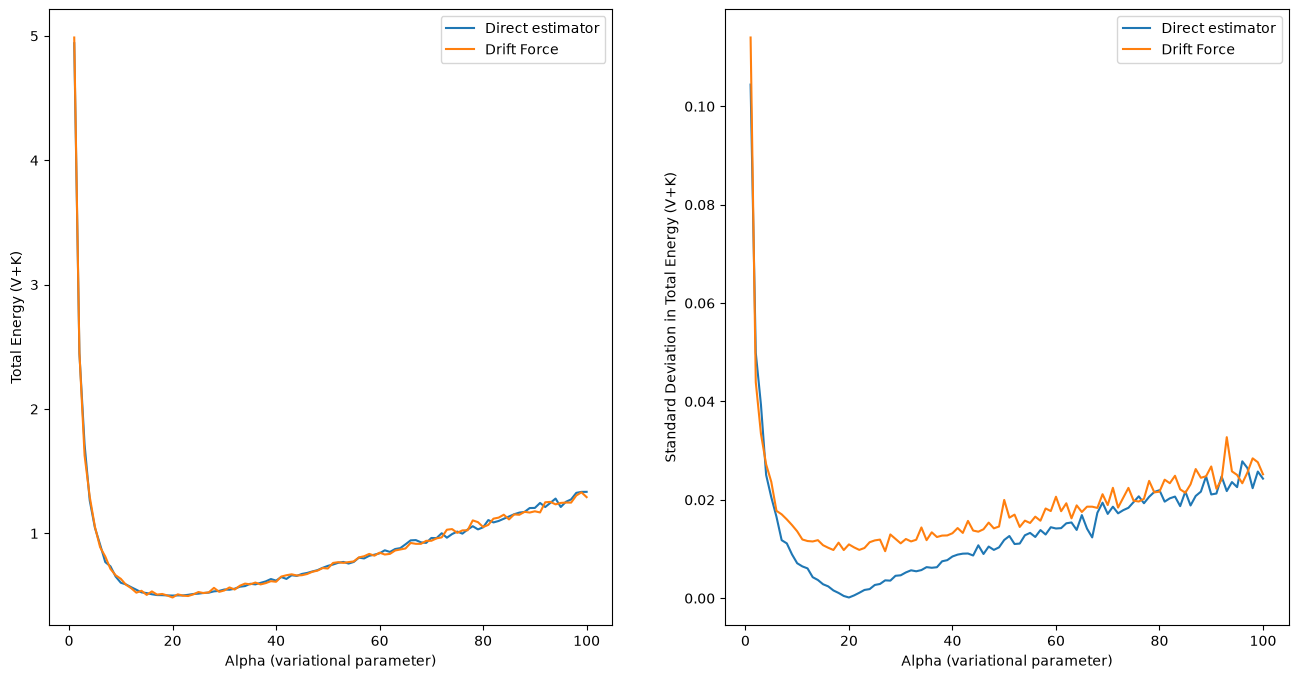

In [12]:
fig = plt.figure(figsize=(16,8))
ax = plt.subplot(1,2,1)
_ = plt.plot(alphas, direct_energies, label="Direct estimator")
_ = plt.plot(alphas, drift_energies, label="Drift Force")
_ = plt.xlabel("Alpha (variational parameter)")
_ = plt.ylabel("Total Energy (V+K)")
_ = ax.legend()

ax = plt.subplot(1,2,2)
_ = plt.plot(alphas, direct_errors, label="Direct estimator")
_ = plt.plot(alphas, drift_errors, label="Drift Force")
_ = plt.xlabel("Alpha (variational parameter)")
_ = plt.ylabel("Standard Deviation in Total Energy (V+K)")
_ = ax.legend()

Finally we can draw the density profile once again, but this time using the ground state wave function:

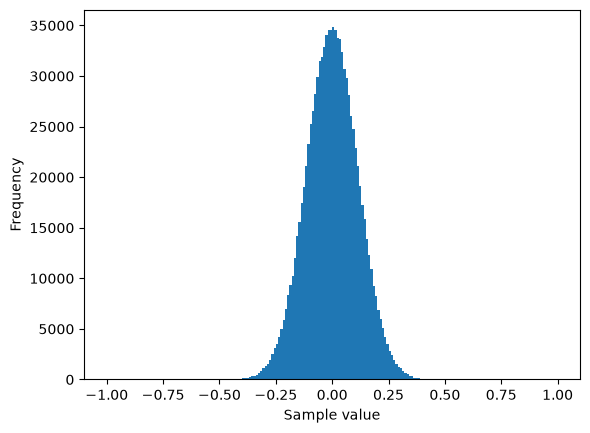

In [18]:
exp.set_alpha(ground_state_alpha)
hist = exp.draw_density_profile(200, -1, 1, N=1_000_000)
